# Estudo dos sinais da 3W para reconstrução de sinal

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ThreeWToolkit.dataset import ParquetDatasetConfig

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

## Parâmetros da análise

In [2]:
DATASET_PATH = Path("../../dataset")

# Analisar inicialmente apenas instâncias reais.
EVENT_TYPES = ["real"]

# Contexto utilizado pelo MOMENT.
WINDOW_SIZE = 64

# Máscaras contíguas que poderão ser testadas posteriormente.
MASK_SIZES = [8, 16, 32]

# Frequência da segunda etapa.
RESAMPLE_RULE = "1min"

# Separação de segmentos quando há lacunas temporais.
GAP_FACTOR = 1.5

SIGNAL_COLUMNS = [
    "ESTADO-DHSV",
    "ESTADO-M1",
    "ESTADO-M2",
    "ESTADO-PXO",
    "ESTADO-SDV-GL",
    "ESTADO-SDV-P",
    "ESTADO-W1",
    "ESTADO-W2",
    "ESTADO-XO",
    "P-MON-CKP",
    "P-PDG",
    "P-TPT",
    "T-JUS-CKP",
    "T-TPT",
]

# Estados discretos: não devem ser agregados por média.
STATE_COLUMNS = [
    "ESTADO-DHSV",
    "ESTADO-M1",
    "ESTADO-M2",
    "ESTADO-PXO",
    "ESTADO-SDV-GL",
    "ESTADO-SDV-P",
    "ESTADO-W1",
    "ESTADO-W2",
    "ESTADO-XO",
]

# Variáveis contínuas.
CONTINUOUS_COLUMNS = [
    "P-MON-CKP",
    "P-PDG",
    "P-TPT",
    "T-JUS-CKP",
    "T-TPT",
]

# Rótulos dos eventos.
EVENT_NAMES = {
    0: "Normal Operation",
    1: "Abrupt Increase of BSW",
    2: "Spurious Closure of DHSV",
    3: "Severe Slugging",
    4: "Flow Instability",
    5: "Rapid Productivity Loss",
    6: "Quick Restriction in PCK",
    7: "Scaling in PCK",
    8: "Hydrate in Production Line",
    9: "Hydrate in Service Line",
}

## Carregar a 3W

In [3]:
dataset = ParquetDatasetConfig(
    path=str(DATASET_PATH),
    event_type=EVENT_TYPES,
).build()

print(f"Total de instâncias: {len(dataset)}")

2026-11-19 16:12:08,879 | INFO | ThreeWToolkit.dataset.parquet_dataset | Dataset found at ../../dataset
2026-11-19 16:12:08,880 | INFO | ThreeWToolkit.dataset.parquet_dataset | Validating dataset integrity...
2026-11-19 16:12:08,880 | INFO | ThreeWToolkit.dataset.parquet_dataset | Dataset integrity check passed!


Total de instâncias: 1119


## Converter cada instância para DataFrame
O rótulo é adicionado ao DataFrame a partir de `event.label`. O identificador da instância fica disponível em `metadata`, para que as análises possam ser agrupadas posteriormente.

In [4]:
events = []

for event_id, event in enumerate(dataset):
    metadata = event.metadata

    df = event.signal.copy()
    df.index = pd.to_datetime(df.index)
    df = df.sort_index()

    # Alinhar os rótulos aos timestamps dos sinais.
    df["class"] = event.label.reindex(df.index)

    missing_columns = [
        col for col in SIGNAL_COLUMNS
        if col not in df.columns
    ]

    if missing_columns:
        print(
            f"Instância {event_id}: colunas ausentes: "
            f"{missing_columns}"
        )
        continue

    df = df[SIGNAL_COLUMNS + ["class"]]

    events.append({
        "event_id": event_id,
        "file_name": str(metadata["file_name"]),
        "event_class": int(metadata["event_class"]),
        "event_name": EVENT_NAMES.get(
            int(metadata["event_class"]), "Unknown"
        ),
        "event_type": metadata["event_type"],
        "data": df,
    })

print(f"Instâncias carregadas: {len(events)}")

events[0]["data"].head()

Instâncias carregadas: 1119


,ESTADO-DHSV,ESTADO-M1,ESTADO-M2,ESTADO-PXO,ESTADO-SDV-GL,ESTADO-SDV-P,ESTADO-W1,ESTADO-W2,ESTADO-XO,P-MON-CKP,P-PDG,P-TPT,T-JUS-CKP,T-TPT,class
timestamp,,,,,,,,,,,,,,,
2017-02-01 01:02:07,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1627884.0,0.0,10074540.0,84.64463,119.0781,<NA>
2017-02-01 01:02:08,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1633397.0,0.0,10074540.0,84.63828,119.0781,<NA>
2017-02-01 01:02:09,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1638909.0,0.0,10074540.0,84.63194,119.0781,<NA>
2017-02-01 01:02:10,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1644422.0,0.0,10074540.0,84.62558,119.0781,<NA>
2017-02-01 01:02:11,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1649934.0,0.0,10074540.0,84.61923,119.0781,<NA>


## Identificar segmentos contínuos
A função identifica lacunas temporais e separa a série em segmentos. Isso é importante porque não devemos construir janelas que atravessem intervalos sem observações.

In [5]:
def split_temporal_segments(index, gap_factor=GAP_FACTOR):
    """
    Divide uma série temporal em segmentos contínuos.

    Uma nova segmentação ocorre quando:
    - o timestamp não é crescente;
    - o intervalo entre observações é maior que
      gap_factor * intervalo mediano.
    """
    index = pd.DatetimeIndex(index)

    if len(index) < 2:
        return [(0, len(index))], np.nan

    delta = np.diff(index.asi8) / 1e9
    positive_delta = delta[delta > 0]

    if len(positive_delta) == 0:
        return [(0, len(index))], np.nan

    median_interval = float(np.median(positive_delta))

    gap_positions = np.where(
        (delta <= 0)
        | (delta > median_interval * gap_factor)
    )[0] + 1

    boundaries = np.concatenate([
        [0],
        gap_positions,
        [len(index)],
    ])

    segments = [
        (int(start), int(end))
        for start, end in zip(
            boundaries[:-1],
            boundaries[1:],
        )
        if end > start
    ]

    return segments, median_interval

## Duração dos períodos de cada rótulo

Aqui calculamos a duração de cada sequência consecutiva de rótulos. Por exemplo, se uma instância apresentar o rótulo 105 durante um trecho contínuo, esse trecho será uma ocorrência transitória.

A duração é estimada como:
- timestamp da última observação;
- menos timestamp da primeira observação;
- mais um intervalo de amostragem, para representar o último ponto.
Assim, uma sequência de 10 observações com intervalo de 1 segundo representa aproximadamente 10 segundos, e não 9.

In [6]:
def extract_label_periods(event, gap_factor=GAP_FACTOR):
    df = event["data"]
    segments, median_interval = split_temporal_segments(
        df.index,
        gap_factor=gap_factor,
    )

    periods = []

    for segment_id, (start, end) in enumerate(segments):
        segment = df.iloc[start:end]

        labels = segment["class"]

        # Não considerar observações sem rótulo.
        valid = labels.notna()
        segment = segment.loc[valid]
        labels = labels.loc[valid]

        if len(segment) == 0:
            continue

        # Identifica mudanças de rótulo.
        groups = labels.ne(labels.shift()).cumsum()

        for _, group in labels.groupby(groups):
            label = int(group.iloc[0])

            timestamps = group.index
            first_timestamp = timestamps[0]
            last_timestamp = timestamps[-1]

            if len(timestamps) > 1:
                local_interval = np.median(
                    np.diff(timestamps.asi8) / 1e9
                )
            else:
                local_interval = median_interval

            if not np.isfinite(local_interval):
                local_interval = 0

            duration_seconds = (
                (last_timestamp - first_timestamp).total_seconds()
                + local_interval
            )

            periods.append({
                "event_id": event["event_id"],
                "file_name": event["file_name"],
                "event_class": event["event_class"],
                "event_name": event["event_name"],
                "segment_id": segment_id,
                "label": label,
                "start": first_timestamp,
                "end": last_timestamp,
                "duration_seconds": duration_seconds,
                "n_samples": len(group),
            })

    return periods

## Executar a análise de duração

In [7]:
periods_raw = []

for event in events:
    periods_raw.extend(extract_label_periods(event))

periods_raw = pd.DataFrame(periods_raw)

periods_raw["duration_minutes"] = (
    periods_raw["duration_seconds"] / 60
)

periods_raw.head()

,event_id,file_name,event_class,event_name,segment_id,label,start,end,duration_seconds,n_samples,duration_minutes
0,0,0/WELL-00001_20170201010207.parquet,0,Normal Operation,0,0,2017-02-01 02:02:08,2017-02-01 07:00:00,17873.0,17873,297.883333
1,1,0/WELL-00001_20170201060114.parquet,0,Normal Operation,0,0,2017-02-01 07:01:15,2017-02-01 12:00:00,17926.0,17926,298.766667
2,2,0/WELL-00001_20170201110124.parquet,0,Normal Operation,0,0,2017-02-01 12:01:25,2017-02-01 17:00:00,17916.0,17916,298.600000
3,3,0/WELL-00001_20170201160311.parquet,0,Normal Operation,0,0,2017-02-01 17:03:12,2017-02-01 22:00:00,17809.0,17809,296.816667
4,4,0/WELL-00001_20170201210228.parquet,0,Normal Operation,0,0,2017-02-01 22:02:29,2017-02-02 03:00:00,17852.0,17852,297.533333


In [8]:
label_duration_summary_raw = (
    periods_raw
    .groupby("label")
    .agg(
        occurrences=("duration_seconds", "count"),
        mean_seconds=("duration_seconds", "mean"),
        median_seconds=("duration_seconds", "median"),
        std_seconds=("duration_seconds", "std"),
        min_seconds=("duration_seconds", "min"),
        max_seconds=("duration_seconds", "max"),
        total_seconds=("duration_seconds", "sum"),
    )
    .sort_index()
)

label_duration_summary_raw

,occurrences,mean_seconds,median_seconds,std_seconds,min_seconds,max_seconds,total_seconds
label,,,,,,,
0,744,19582.524194,17872.0,19187.637939,374.0,234302.0,14569398.0
1,4,2445.750000,2135.5,1730.662373,872.0,4640.0,9783.0
2,11,1934.000000,1120.0,2534.159663,156.0,8986.0,21274.0
3,32,17785.000000,17926.0,626.903913,14384.0,17975.0,569120.0
4,343,7156.093294,7158.0,187.419714,6967.0,10537.0,2454540.0
5,7,1886.428571,985.0,2581.323295,110.0,7529.0,13205.0
6,6,2214.166667,551.0,2953.630879,154.0,6868.0,13285.0
7,5,6067.800000,3172.0,8493.732760,948.0,21162.0,30339.0
8,12,11743.333333,8222.0,11302.979465,1963.0,37869.0,140920.0


In [9]:
transient_105_raw = periods_raw.query("label == 105")

print(
    f"Ocorrências do rótulo 105: "
    f"{len(transient_105_raw)}"
)

transient_105_raw[
    [
        "file_name",
        "event_class",
        "start",
        "end",
        "duration_seconds",
        "duration_minutes",
        "n_samples",
    ]
]

Ocorrências do rótulo 105: 11


,file_name,event_class,start,end,duration_seconds,duration_minutes,n_samples
1037,5/WELL-00015_20170620122925.parquet,5,2017-06-20 16:39:52,2017-06-20 19:12:51,9180.0,153.000000,9180
1040,5/WELL-00016_20180405005319.parquet,5,2018-04-05 02:22:55,2018-04-05 02:57:05,2051.0,34.183333,2051
1043,5/WELL-00016_20180426131710.parquet,5,2018-04-26 14:25:31,2018-04-26 14:44:04,1114.0,18.566667,1114
1045,5/WELL-00016_20180426135108.parquet,5,2018-04-26 14:57:23,2018-04-26 15:40:06,2564.0,42.733333,2564
1048,5/WELL-00016_20180517212322.parquet,5,2018-05-17 22:45:36,2018-05-17 23:37:26,3111.0,51.850000,3111
1051,5/WELL-00020_20140314144539.parquet,5,2014-03-14 17:50:47,2014-03-16 08:02:53,137527.0,2292.116667,137527
1054,5/WELL-00020_20140317130658.parquet,5,2014-03-17 16:34:19,2014-03-18 01:13:35,31157.0,519.283333,31157
1057,5/WELL-00020_20140318005900.parquet,5,2014-03-18 02:59:27,2014-03-18 13:57:58,39512.0,658.533333,39512
1059,5/WELL-00020_20140318135038.parquet,5,2014-03-18 17:06:03,2014-03-19 02:00:00,32038.0,533.966667,32038
1061,5/WELL-00020_20140319021600.parquet,5,2014-03-19 06:01:30,2014-03-19 11:00:00,17911.0,298.516667,17911


In [10]:
transient_duration_by_event_raw = (
    periods_raw[periods_raw["label"] >= 100]
    .groupby(["label", "event_class", "event_name"])
    .agg(
        occurrences=("duration_seconds", "count"),
        mean_seconds=("duration_seconds", "mean"),
        median_seconds=("duration_seconds", "median"),
        min_seconds=("duration_seconds", "min"),
        max_seconds=("duration_seconds", "max"),
    )
    .reset_index()
)

transient_duration_by_event_raw

,label,event_class,event_name,occurrences,mean_seconds,median_seconds,min_seconds,max_seconds
0,101,1,Abrupt Increase of BSW,4,16335.000000,9817.5,6615.0,39090.0
1,102,2,Spurious Closure of DHSV,22,4049.590909,2350.5,937.0,11608.0
2,105,5,Rapid Productivity Loss,11,29152.000000,17911.0,1114.0,137527.0
3,106,6,Quick Restriction in PCK,6,1094.833333,735.5,524.0,2485.0
4,107,7,Scaling in PCK,36,185293.944444,144622.0,14966.0,715647.0
5,108,8,Hydrate in Production Line,14,261101.285714,226854.0,82362.0,598945.0
6,109,9,Hydrate in Service Line,14,13960.214286,12332.5,182.0,49161.0


## Contagem de janelas válidas

A contagem é feita dentro de cada segmento contínuo, evitando janelas que atravessem lacunas. Vamos contar:
- janelas candidatas;
- janelas com todos os valores das 14 variáveis disponíveis;
- janelas com pelo menos 95% das linhas completas.
Isso nos dará uma estimativa da quantidade de janelas que podem ser usadas para reconstrução.

In [11]:
def count_windows(event, window_size=WINDOW_SIZE):
    df = event["data"]
    segments, median_interval = split_temporal_segments(df.index)

    results = []

    for segment_id, (start, end) in enumerate(segments):
        segment = df.iloc[start:end]
        X = segment[SIGNAL_COLUMNS].to_numpy(dtype=float)

        n = len(X)

        if n < window_size:
            continue

        row_valid = np.isfinite(X).all(axis=1)

        n_candidates = n - window_size + 1
        complete_windows = 0
        coverage_95_windows = 0

        for i in range(n_candidates):
            window_valid = row_valid[i:i + window_size]

            valid_fraction = window_valid.mean()

            if valid_fraction == 1.0:
                complete_windows += 1

            if valid_fraction >= 0.95:
                coverage_95_windows += 1

        results.append({
            "event_id": event["event_id"],
            "file_name": event["file_name"],
            "event_class": event["event_class"],
            "event_name": event["event_name"],
            "segment_id": segment_id,
            "n_samples": n,
            "duration_seconds": (
                (segment.index[-1] - segment.index[0]).total_seconds()
                + (median_interval or 0)
            ),
            "candidate_windows": n_candidates,
            "complete_windows": complete_windows,
            "windows_95pct_coverage": coverage_95_windows,
        })

    return results

In [12]:
window_results_raw = []

for event in events:
    window_results_raw.extend(count_windows(event))

window_results_raw = pd.DataFrame(window_results_raw)

window_results_raw.head()

,event_id,file_name,event_class,event_name,segment_id,n_samples,duration_seconds,candidate_windows,complete_windows,windows_95pct_coverage
0,0,0/WELL-00001_20170201010207.parquet,0,Normal Operation,0,21474,21474.0,21411,21411,21411
1,1,0/WELL-00001_20170201060114.parquet,0,Normal Operation,0,21527,21527.0,21464,21464,21464
2,2,0/WELL-00001_20170201110124.parquet,0,Normal Operation,0,21517,21517.0,21454,21454,21454
3,3,0/WELL-00001_20170201160311.parquet,0,Normal Operation,0,21410,21410.0,21347,21347,21347
4,4,0/WELL-00001_20170201210228.parquet,0,Normal Operation,0,21453,21453.0,21390,21390,21390


In [13]:
window_summary_raw = (
    window_results_raw
    .groupby(["event_class", "event_name"])
    .agg(
        segments=("segment_id", "count"),
        samples=("n_samples", "sum"),
        candidate_windows=("candidate_windows", "sum"),
        complete_windows=("complete_windows", "sum"),
        windows_95pct_coverage=("windows_95pct_coverage", "sum"),
    )
    .reset_index()
)

window_summary_raw

,event_class,event_name,segments,samples,candidate_windows,complete_windows,windows_95pct_coverage
0,0,Normal Operation,594,12158183,12120761,4437908,4437908
1,1,Abrupt Increase of BSW,4,236794,236542,218634,218634
2,2,Spurious Closure of DHSV,22,277001,275615,10275,10275
3,3,Severe Slugging,32,684352,682336,21513,21513
4,4,Flow Instability,343,3689683,3668074,495810,495810
5,5,Rapid Productivity Loss,11,439408,438715,430030,430039
6,6,Quick Restriction in PCK,6,77477,77099,0,0
7,7,Scaling in PCK,36,7864945,7862677,324573,324585
8,8,Hydrate in Production Line,14,4809035,4808153,0,0
9,9,Hydrate in Service Line,57,2635372,2631781,209865,209865


In [14]:
mask_availability_raw = []

for mask_size in MASK_SIZES:
    mask_availability_raw.append({
        "mask_size": mask_size,
        "window_size": WINDOW_SIZE,
        "masked_fraction": mask_size / WINDOW_SIZE,
        "complete_windows": window_summary_raw[
            "complete_windows"
        ].sum(),
    })

pd.DataFrame(mask_availability_raw)

,mask_size,window_size,masked_fraction,complete_windows
0,8,64,0.125,6148608
1,16,64,0.250,6148608
2,32,64,0.500,6148608


## Subamostragem para 1 minuto
Agora vamos repetir a análise após converter cada instância para uma resolução de um minuto.

Para evitar criar valores artificiais nos estados das válvulas:
- variáveis discretas: último valor observado no minuto;
- variáveis contínuas: mediana das observações no minuto;
- rótulo class: último rótulo observado no minuto.
A escolha de usar o último rótulo é importante: estamos representando o estado do processo no instante amostrado ao final de cada minuto. Um transitório que ocorra e termine antes desse instante poderá desaparecer — e isso é justamente algo que queremos medir.

In [15]:
def resample_event(event, rule=RESAMPLE_RULE):
    df = event["data"].copy()

    aggregation = {
        col: "last"
        for col in STATE_COLUMNS
    }

    aggregation.update({
        col: "median"
        for col in CONTINUOUS_COLUMNS
    })

    aggregation["class"] = "last"

    resampled = (
        df
        .resample(rule)
        .agg(aggregation)
        .dropna(how="all", subset=SIGNAL_COLUMNS)
    )

    return {
        **event,
        "data": resampled,
    }

In [16]:
events_1min = [
    resample_event(event)
    for event in events
]

print(f"Instâncias: {len(events_1min)}")

events_1min[0]["data"].head()

Instâncias: 1119


,ESTADO-DHSV,ESTADO-M1,ESTADO-M2,ESTADO-PXO,ESTADO-SDV-GL,ESTADO-SDV-P,ESTADO-W1,ESTADO-W2,ESTADO-XO,P-MON-CKP,P-PDG,P-TPT,T-JUS-CKP,T-TPT,class
timestamp,,,,,,,,,,,,,,,
2017-02-01 01:02:00,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1680365.0,0.0,10074540.0,84.568430,119.0782,<NA>
2017-02-01 01:03:00,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1390248.5,0.0,10074540.0,84.787730,119.0784,<NA>
2017-02-01 01:04:00,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1547687.5,0.0,10074540.0,84.150635,119.0787,<NA>
2017-02-01 01:05:00,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1756909.0,0.0,10074540.0,84.866535,119.0790,<NA>
2017-02-01 01:06:00,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1546471.5,0.0,10074540.0,84.573845,119.0792,<NA>


## Repetir os estudos após a subamostragem

In [17]:
periods_1min = []

for event in events_1min:
    periods_1min.extend(extract_label_periods(event))

periods_1min = pd.DataFrame(periods_1min)

periods_1min["duration_minutes"] = (
    periods_1min["duration_seconds"] / 60
)

label_duration_summary_1min = (
    periods_1min
    .groupby("label")
    .agg(
        occurrences=("duration_seconds", "count"),
        mean_seconds=("duration_seconds", "mean"),
        median_seconds=("duration_seconds", "median"),
        std_seconds=("duration_seconds", "std"),
        min_seconds=("duration_seconds", "min"),
        max_seconds=("duration_seconds", "max"),
        total_seconds=("duration_seconds", "sum"),
    )
    .sort_index()
)

label_duration_summary_1min

,occurrences,mean_seconds,median_seconds,std_seconds,min_seconds,max_seconds,total_seconds
label,,,,,,,
0,690,19640.782609,17880.0,19458.207113,300.0,234240.0,13552140.0
1,4,2535.000000,2250.0,1708.595915,960.0,4680.0,10140.0
2,11,1996.363636,1200.0,2540.359316,240.0,9060.0,21960.0
3,33,17247.272727,17940.0,3039.382413,720.0,18000.0,569160.0
4,344,7152.209302,7200.0,400.227053,720.0,10560.0,2460360.0
5,7,1800.000000,900.0,2606.376795,120.0,7560.0,12600.0
6,6,2260.000000,600.0,2944.690136,180.0,6900.0,13560.0
7,5,6120.000000,3180.0,8509.535828,960.0,21240.0,30600.0
8,12,11805.000000,8280.0,11298.354265,2040.0,37920.0,141660.0


In [18]:
transient_105_1min = periods_1min.query("label == 105")

transient_105_1min[
    [
        "file_name",
        "event_class",
        "start",
        "end",
        "duration_seconds",
        "duration_minutes",
        "n_samples",
    ]
]

,file_name,event_class,start,end,duration_seconds,duration_minutes,n_samples
984,5/WELL-00015_20170620122925.parquet,5,2017-06-20 16:39:00,2017-06-20 19:11:00,9180.0,153.0,153
987,5/WELL-00016_20180405005319.parquet,5,2018-04-05 02:22:00,2018-04-05 02:56:00,2100.0,35.0,35
990,5/WELL-00016_20180426131710.parquet,5,2018-04-26 14:25:00,2018-04-26 14:44:00,1200.0,20.0,20
992,5/WELL-00016_20180426135108.parquet,5,2018-04-26 14:57:00,2018-04-26 15:39:00,2580.0,43.0,43
995,5/WELL-00016_20180517212322.parquet,5,2018-05-17 22:45:00,2018-05-17 23:36:00,3120.0,52.0,52
998,5/WELL-00020_20140314144539.parquet,5,2014-03-14 17:50:00,2014-03-16 07:59:00,137400.0,2290.0,2290
1001,5/WELL-00020_20140317130658.parquet,5,2014-03-17 16:34:00,2014-03-18 01:12:00,31140.0,519.0,519
1004,5/WELL-00020_20140318005900.parquet,5,2014-03-18 02:59:00,2014-03-18 13:57:00,39540.0,659.0,659
1006,5/WELL-00020_20140318135038.parquet,5,2014-03-18 17:06:00,2014-03-19 02:00:00,32100.0,535.0,535
1008,5/WELL-00020_20140319021600.parquet,5,2014-03-19 06:01:00,2014-03-19 11:00:00,18000.0,300.0,300


## Disponibilidade de janelas em 1 minuto

In [19]:
window_results_1min = []

for event in events_1min:
    window_results_1min.extend(count_windows(event))

window_results_1min = pd.DataFrame(window_results_1min)

window_summary_1min = (
    window_results_1min
    .groupby(["event_class", "event_name"])
    .agg(
        segments=("segment_id", "count"),
        samples=("n_samples", "sum"),
        candidate_windows=("candidate_windows", "sum"),
        complete_windows=("complete_windows", "sum"),
        windows_95pct_coverage=("windows_95pct_coverage", "sum"),
    )
    .reset_index()
)

window_summary_1min

,event_class,event_name,segments,samples,candidate_windows,complete_windows,windows_95pct_coverage
0,0,Normal Operation,538,182867,148973,61263,61263
1,1,Abrupt Increase of BSW,4,3952,3700,3462,3462
2,2,Spurious Closure of DHSV,22,4635,3249,110,110
3,3,Severe Slugging,32,11331,9315,298,298
4,4,Flow Instability,343,61917,40308,5446,5446
5,5,Rapid Productivity Loss,11,7299,6606,6543,6543
6,6,Quick Restriction in PCK,6,1295,917,0,0
7,7,Scaling in PCK,41,131115,128532,5164,5164
8,8,Hydrate in Production Line,15,80163,79218,0,0
9,9,Hydrate in Service Line,58,43972,40318,3130,3130


## Comparar durações dos rótulos

In [20]:
duration_comparison = (
    label_duration_summary_raw[
        ["occurrences", "mean_seconds", "median_seconds", "total_seconds"]
    ]
    .add_suffix("_raw")
    .join(
        label_duration_summary_1min[
            ["occurrences", "mean_seconds", "median_seconds", "total_seconds"]
        ].add_suffix("_1min"),
        how="outer",
    )
)

duration_comparison

,occurrences_raw,mean_seconds_raw,median_seconds_raw,total_seconds_raw,occurrences_1min,mean_seconds_1min,median_seconds_1min,total_seconds_1min
label,,,,,,,,
0,744,19582.524194,17872.0,14569398.0,690,19640.782609,17880.0,13552140.0
1,4,2445.750000,2135.5,9783.0,4,2535.000000,2250.0,10140.0
2,11,1934.000000,1120.0,21274.0,11,1996.363636,1200.0,21960.0
3,32,17785.000000,17926.0,569120.0,33,17247.272727,17940.0,569160.0
4,343,7156.093294,7158.0,2454540.0,344,7152.209302,7200.0,2460360.0
5,7,1886.428571,985.0,13205.0,7,1800.000000,900.0,12600.0
6,6,2214.166667,551.0,13285.0,6,2260.000000,600.0,13560.0
7,5,6067.800000,3172.0,30339.0,5,6120.000000,3180.0,30600.0
8,12,11743.333333,8222.0,140920.0,12,11805.000000,8280.0,141660.0


## Comparar disponibilidade de janelas

In [21]:
window_comparison = (
    window_summary_raw
    .set_index("event_class")[
        [
            "candidate_windows",
            "complete_windows",
            "windows_95pct_coverage",
        ]
    ]
    .add_suffix("_raw")
    .join(
        window_summary_1min
        .set_index("event_class")[
            [
                "candidate_windows",
                "complete_windows",
                "windows_95pct_coverage",
            ]
        ].add_suffix("_1min"),
        how="outer",
    )
)

window_comparison

,candidate_windows_raw,complete_windows_raw,windows_95pct_coverage_raw,candidate_windows_1min,complete_windows_1min,windows_95pct_coverage_1min
event_class,,,,,,
0,12120761,4437908,4437908,148973,61263,61263
1,236542,218634,218634,3700,3462,3462
2,275615,10275,10275,3249,110,110
3,682336,21513,21513,9315,298,298
4,3668074,495810,495810,40308,5446,5446
5,438715,430030,430039,6606,6543,6543
6,77099,0,0,917,0,0
7,7862677,324573,324585,128532,5164,5164
8,4808153,0,0,79218,0,0


## Visualizar a comparação das durações transitórias

2026-11-19 16:16:16,183 | INFO | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-11-19 16:16:16,340 | INFO | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


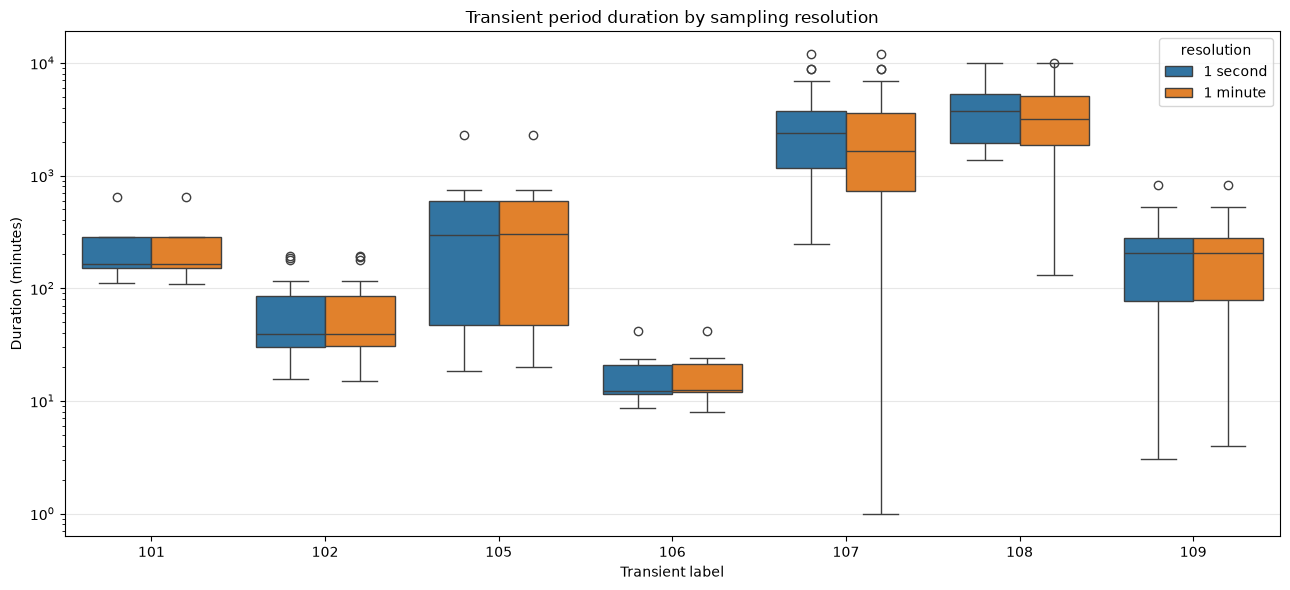

In [22]:
transient_comparison = pd.concat([
    periods_raw.assign(resolution="1 second"),
    periods_1min.assign(resolution="1 minute"),
])

transient_comparison = transient_comparison[
    transient_comparison["label"] >= 100
]

plt.figure(figsize=(13, 6))

sns.boxplot(
    data=transient_comparison,
    x="label",
    y="duration_minutes",
    hue="resolution",
)

plt.yscale("log")
plt.xlabel("Transient label")
plt.ylabel("Duration (minutes)")
plt.title("Transient period duration by sampling resolution")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Visualizar a quantidade de janelas completas

2026-11-19 16:16:17,129 | INFO | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-11-19 16:16:17,136 | INFO | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


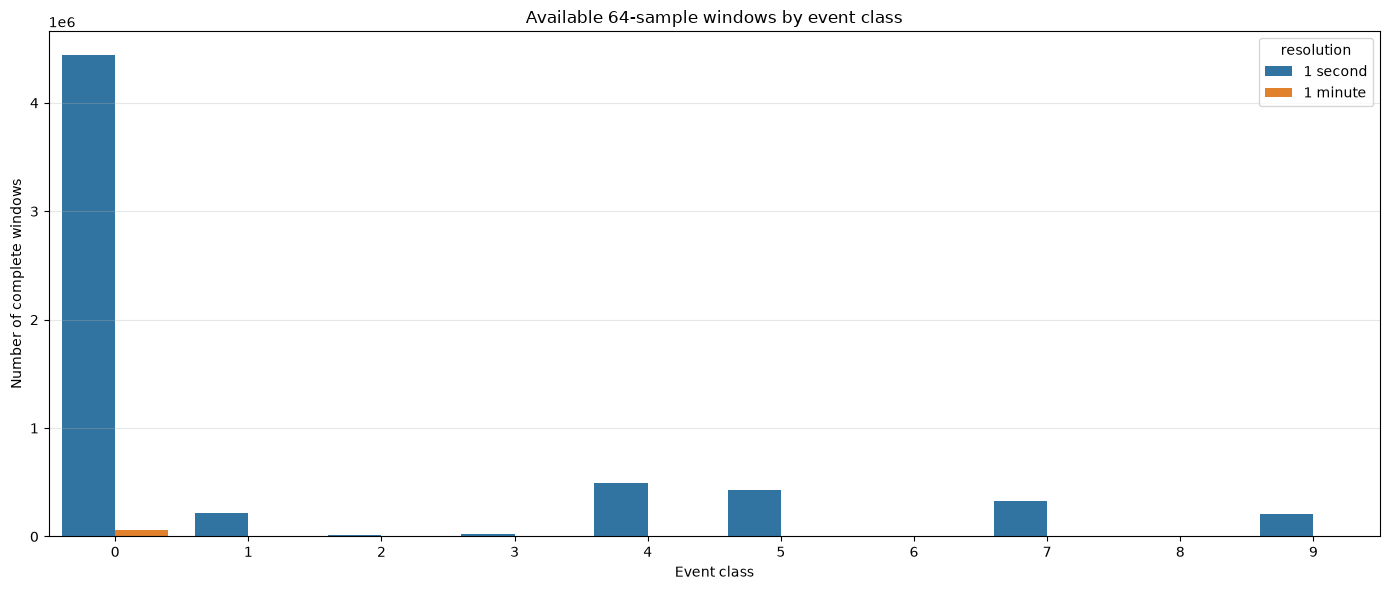

In [23]:
comparison_plot = pd.concat([
    window_summary_raw.assign(resolution="1 second"),
    window_summary_1min.assign(resolution="1 minute"),
])

plt.figure(figsize=(14, 6))

sns.barplot(
    data=comparison_plot,
    x="event_class",
    y="complete_windows",
    hue="resolution",
)

plt.xlabel("Event class")
plt.ylabel("Number of complete windows")
plt.title("Available 64-sample windows by event class")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Gerar os períodos diretamente das séries de rótulos

Nesta versão, cada período é representado pelo intervalo [start, end_exclusive). O limite final é estimado adicionando o intervalo de amostragem ao último timestamp do período. Isso facilita comparar intervalos de diferentes resoluções.

In [24]:
def extract_periods_from_labels(
    labels,
    event,
    resolution,
    gap_factor=GAP_FACTOR,
):
    labels = labels.copy()
    labels.index = pd.to_datetime(labels.index)
    labels = labels.sort_index().dropna()

    if labels.empty:
        return []

    segments, median_interval = split_temporal_segments(
        labels.index,
        gap_factor=gap_factor,
    )

    periods = []

    for segment_id, (start, end) in enumerate(segments):
        segment_labels = labels.iloc[start:end]

        if segment_labels.empty:
            continue

        groups = segment_labels.ne(
            segment_labels.shift()
        ).cumsum()

        for _, group in segment_labels.groupby(groups):
            timestamps = group.index

            if len(timestamps) > 1:
                local_interval = np.median(
                    np.diff(timestamps.asi8) / 1e9
                )
            else:
                local_interval = median_interval

            if not np.isfinite(local_interval):
                local_interval = 0.0

            period_start = timestamps[0]
            period_end = timestamps[-1] + pd.to_timedelta(
                local_interval,
                unit="s",
            )

            periods.append({
                "event_id": event["event_id"],
                "file_name": event["file_name"],
                "event_class": event["event_class"],
                "event_name": event["event_name"],
                "resolution": resolution,
                "segment_id": segment_id,
                "label": int(group.iloc[0]),
                "start": period_start,
                "end_exclusive": period_end,
                "duration_seconds": (
                    period_end - period_start
                ).total_seconds(),
                "n_samples": len(group),
            })

    return periods

## Criar as séries de rótulos para as duas resoluções

A série de 1 minuto é gerada diretamente a partir dos dados originais, sem depender da disponibilidade dos sinais.

In [25]:
periods_raw_reference = []
periods_1min_reference = []

for event in events:
    raw_labels = event["data"]["class"]

    # Resolução original
    periods_raw_reference.extend(
        extract_periods_from_labels(
            raw_labels,
            event,
            resolution="1s",
        )
    )

    # Último rótulo observado em cada minuto.
    labels_1min = (
        raw_labels
        .resample("1min")
        .last()
        .dropna()
    )

    periods_1min_reference.extend(
        extract_periods_from_labels(
            labels_1min,
            event,
            resolution="1min",
        )
    )

periods_raw_reference = pd.DataFrame(
    periods_raw_reference
)

periods_1min_reference = pd.DataFrame(
    periods_1min_reference
)

display(periods_raw_reference.head())
display(periods_1min_reference.head())

,event_id,file_name,event_class,event_name,resolution,segment_id,label,start,end_exclusive,duration_seconds,n_samples
0,0,0/WELL-00001_20170201010207.parquet,0,Normal Operation,1s,0,0,2017-02-01 02:02:08,2017-02-01 07:00:01,17873.0,17873
1,1,0/WELL-00001_20170201060114.parquet,0,Normal Operation,1s,0,0,2017-02-01 07:01:15,2017-02-01 12:00:01,17926.0,17926
2,2,0/WELL-00001_20170201110124.parquet,0,Normal Operation,1s,0,0,2017-02-01 12:01:25,2017-02-01 17:00:01,17916.0,17916
3,3,0/WELL-00001_20170201160311.parquet,0,Normal Operation,1s,0,0,2017-02-01 17:03:12,2017-02-01 22:00:01,17809.0,17809
4,4,0/WELL-00001_20170201210228.parquet,0,Normal Operation,1s,0,0,2017-02-01 22:02:29,2017-02-02 03:00:01,17852.0,17852


,event_id,file_name,event_class,event_name,resolution,segment_id,label,start,end_exclusive,duration_seconds,n_samples
0,0,0/WELL-00001_20170201010207.parquet,0,Normal Operation,1min,0,0,2017-02-01 02:03:00,2017-02-01 07:01:00,17880.0,298
1,1,0/WELL-00001_20170201060114.parquet,0,Normal Operation,1min,0,0,2017-02-01 07:02:00,2017-02-01 12:01:00,17940.0,299
2,2,0/WELL-00001_20170201110124.parquet,0,Normal Operation,1min,0,0,2017-02-01 12:02:00,2017-02-01 17:01:00,17940.0,299
3,3,0/WELL-00001_20170201160311.parquet,0,Normal Operation,1min,0,0,2017-02-01 17:04:00,2017-02-01 22:01:00,17820.0,297
4,4,0/WELL-00001_20170201210228.parquet,0,Normal Operation,1min,0,0,2017-02-01 22:03:00,2017-02-02 03:01:00,17880.0,298


## Verificar a quantidade de períodos por rótulo

Essa tabela permite conferir se os resultados obtidos com a série de rótulos independente são consistentes com os resultados anteriores.

In [26]:
period_count_comparison = (
    periods_raw_reference
    .groupby("label")
    .size()
    .rename("occurrences_raw")
    .to_frame()
    .join(
        periods_1min_reference
        .groupby("label")
        .size()
        .rename("occurrences_1min"),
        how="outer",
    )
    .fillna(0)
    .astype(int)
)

period_count_comparison

,occurrences_raw,occurrences_1min
label,,
0,744,744
1,4,4
2,11,11
3,32,32
4,343,343
5,7,7
6,6,6
7,5,5
8,12,12


## Identificar períodos preservados, desaparecidos, divididos ou unidos
Para fazer essa comparação, vamos considerar que dois períodos correspondem entre as resoluções quando seus intervalos temporais se sobrepõem.

A comparação é feita por event_id e label, pois não podemos associar períodos de instâncias diferentes, mesmo que tenham o mesmo rótulo.

In [27]:
def calculate_overlap(period_a, period_b):
    overlap_start = max(
        period_a["start"],
        period_b["start"],
    )

    overlap_end = min(
        period_a["end_exclusive"],
        period_b["end_exclusive"],
    )

    overlap = max(
        0.0,
        (overlap_end - overlap_start).total_seconds(),
    )

    return overlap

Relacionar períodos das duas resoluções:

In [28]:
def match_periods(raw_periods, resampled_periods):
    matches = []

    group_columns = ["event_id", "label"]

    raw_groups = {
        key: group
        for key, group in raw_periods.groupby(group_columns)
    }

    resampled_groups = {
        key: group
        for key, group in resampled_periods.groupby(group_columns)
    }

    all_keys = set(raw_groups) | set(resampled_groups)

    for key in all_keys:
        raw_group = raw_groups.get(
            key,
            pd.DataFrame(),
        )

        resampled_group = resampled_groups.get(
            key,
            pd.DataFrame(),
        )

        raw_records = raw_group.to_dict("records")
        resampled_records = resampled_group.to_dict("records")

        for raw_id, raw_period in enumerate(raw_records):
            overlapping = []

            for minute_id, minute_period in enumerate(
                resampled_records
            ):
                overlap = calculate_overlap(
                    raw_period,
                    minute_period,
                )

                if overlap > 0:
                    overlapping.append({
                        "minute_id": minute_id,
                        "overlap_seconds": overlap,
                    })

            matches.append({
                "event_id": key[0],
                "label": key[1],
                "raw_id": raw_id,
                "raw_start": raw_period["start"],
                "raw_end": raw_period["end_exclusive"],
                "raw_duration": raw_period["duration_seconds"],
                "n_overlapping_1min_periods": len(overlapping),
                "overlapping_1min_ids": [
                    item["minute_id"]
                    for item in overlapping
                ],
                "overlap_seconds": sum(
                    item["overlap_seconds"]
                    for item in overlapping
                ),
            })

    return pd.DataFrame(matches)


period_matches = match_periods(
    periods_raw_reference,
    periods_1min_reference,
)

period_matches.head()

,event_id,label,raw_id,raw_start,raw_end,raw_duration,n_overlapping_1min_periods,overlapping_1min_ids,overlap_seconds
0,521,0,0,2017-08-26 02:02:08,2017-08-26 07:00:01,17873.0,1,[0],17821.0
1,125,0,0,2017-02-14 12:00:57,2017-02-14 17:00:01,17944.0,1,[0],17941.0
2,259,0,0,2017-08-04 21:00:01,2017-08-05 01:58:26,17905.0,1,[0],17846.0
3,782,4,0,2014-01-25 04:00:34,2014-01-25 06:00:01,7167.0,1,[0],7141.0
4,1031,107,0,2016-07-12 20:38:47,2016-07-17 03:06:30,368863.0,1,[0],368863.0


## Identificar períodos desaparecidos e divididos

A classificação abaixo é feita do ponto de vista dos períodos originais:
- `disappeared`: não existe nenhum período de 1 minuto sobreposto;
- `preserved`: existe exatamente um período correspondente;
- `split`: o período original se sobrepõe a mais de um período de 1 minuto.

In [29]:
def classify_raw_periods(matches):
    result = matches.copy()

    result["status"] = np.select(
        [
            result["n_overlapping_1min_periods"] == 0,
            result["n_overlapping_1min_periods"] == 1,
            result["n_overlapping_1min_periods"] > 1,
        ],
        [
            "disappeared",
            "preserved",
            "split",
        ],
        default="unknown",
    )

    return result


period_matches = classify_raw_periods(period_matches)

period_matches["status"].value_counts()

status
preserved    1274
Name: count, dtype: int64

## Identificar períodos unidos

Agora fazemos a análise inversa: cada período de 1 minuto pode se sobrepor a um ou mais períodos originais.

Se um período de 1 minuto se sobrepuser a mais de um período original, ele pode representar uma união de períodos separados na resolução original.

In [30]:
def classify_resampled_periods(raw_periods, resampled_periods):
    results = []

    for key, minute_group in resampled_periods.groupby(
        ["event_id", "label"]
    ):
        raw_group = raw_periods[
            (raw_periods["event_id"] == key[0])
            & (raw_periods["label"] == key[1])
        ]

        for minute_id, minute_period in enumerate(
            minute_group.to_dict("records")
        ):
            overlapping_raw = []

            for raw_id, raw_period in enumerate(
                raw_group.to_dict("records")
            ):
                overlap = calculate_overlap(
                    raw_period,
                    minute_period,
                )

                if overlap > 0:
                    overlapping_raw.append(raw_id)

            results.append({
                "event_id": key[0],
                "label": key[1],
                "minute_id": minute_id,
                "minute_start": minute_period["start"],
                "minute_end": minute_period["end_exclusive"],
                "minute_duration": minute_period["duration_seconds"],
                "n_overlapping_raw_periods": len(overlapping_raw),
                "overlapping_raw_ids": overlapping_raw,
                "status": (
                    "merged"
                    if len(overlapping_raw) > 1
                    else "preserved"
                    if len(overlapping_raw) == 1
                    else "new"
                ),
            })

    return pd.DataFrame(results)


resampled_period_matches = classify_resampled_periods(
    periods_raw_reference,
    periods_1min_reference,
)

resampled_period_matches["status"].value_counts()

status
preserved    1274
Name: count, dtype: int64

In [31]:
raw_status_summary = (
    period_matches
    .groupby(["label", "status"])
    .size()
    .unstack(fill_value=0)
)

minute_status_summary = (
    resampled_period_matches
    .groupby(["label", "status"])
    .size()
    .unstack(fill_value=0)
)

period_status_comparison = (
    raw_status_summary
    .add_prefix("raw_")
    .join(
        minute_status_summary.add_prefix("1min_"),
        how="outer",
    )
    .fillna(0)
    .astype(int)
)

period_status_comparison

status,raw_preserved,1min_preserved
label,,
0,744,744
1,4,4
2,11,11
3,32,32
4,343,343
5,7,7
6,6,6
7,5,5
8,12,12


## Medir a alteração na duração de cada período
A comparação anterior identifica quantos períodos se relacionam. Agora vamos quantificar a diferença de duração.

Para períodos preservados, podemos comparar diretamente a duração original com a duração após a subamostragem. Para períodos divididos, somaremos as durações dos períodos de 1 minuto que se sobrepõem ao período original.

In [32]:
def compare_period_durations(
    raw_periods,
    resampled_periods,
    matches,
):
    results = []

    for match in matches.to_dict("records"):
        raw_period = raw_periods[
            (raw_periods["event_id"] == match["event_id"])
            & (raw_periods["label"] == match["label"])
        ].iloc[match["raw_id"]]

        corresponding = resampled_periods[
            (resampled_periods["event_id"] == match["event_id"])
            & (resampled_periods["label"] == match["label"])
        ]

        corresponding = corresponding.iloc[
            match["overlapping_1min_ids"]
        ]

        raw_duration = raw_period["duration_seconds"]

        resampled_duration = (
            corresponding["duration_seconds"].sum()
        )

        difference = resampled_duration - raw_duration

        results.append({
            "event_id": match["event_id"],
            "file_name": raw_period["file_name"],
            "label": match["label"],
            "raw_duration_seconds": raw_duration,
            "resampled_duration_seconds": resampled_duration,
            "difference_seconds": difference,
            "difference_percent": (
                100 * difference / raw_duration
                if raw_duration > 0
                else np.nan
            ),
            "status": match["status"],
        })

    return pd.DataFrame(results)


period_duration_comparison = compare_period_durations(
    periods_raw_reference,
    periods_1min_reference,
    period_matches,
)

period_duration_comparison.head()

,event_id,file_name,label,raw_duration_seconds,resampled_duration_seconds,difference_seconds,difference_percent,status
0,521,0/WELL-00006_20170826010207.parquet,0,17873.0,17880.0,7.0,0.039165,preserved
1,125,0/WELL-00002_20170214110056.parquet,0,17944.0,18000.0,56.0,0.312082,preserved
2,259,0/WELL-00002_20170804200000.parquet,0,17905.0,17880.0,-25.0,-0.139626,preserved
3,782,4/WELL-00002_20140125030033.parquet,4,7167.0,7200.0,33.0,0.460444,preserved
4,1031,7/WELL-00024_20160712123044.parquet,107,368863.0,368940.0,77.0,0.020875,preserved


In [33]:
duration_change_summary = (
    period_duration_comparison
    .groupby(["label", "status"])
    .agg(
        periods=("event_id", "count"),
        mean_raw_seconds=("raw_duration_seconds", "mean"),
        mean_1min_seconds=("resampled_duration_seconds", "mean"),
        mean_difference_seconds=("difference_seconds", "mean"),
        median_difference_percent=("difference_percent", "median"),
        max_absolute_difference_seconds=(
            "difference_seconds",
            lambda x: x.abs().max(),
        ),
    )
    .reset_index()
)

duration_change_summary

,label,status,periods,mean_raw_seconds,mean_1min_seconds,mean_difference_seconds,median_difference_percent,max_absolute_difference_seconds
0,0,preserved,744,19582.524194,19571.129032,-11.395161,-0.044573,115.0
1,1,preserved,4,2445.750000,2535.000000,89.250000,6.338879,118.0
2,2,preserved,11,1934.000000,1996.363636,62.363636,3.211009,112.0
3,3,preserved,32,17785.000000,17803.125000,18.125000,0.133958,54.0
4,4,preserved,343,7156.093294,7174.285714,18.192420,0.292520,59.0
5,5,preserved,7,1886.428571,1945.714286,59.285714,8.925870,99.0
6,6,preserved,6,2214.166667,2260.000000,45.833333,9.926984,86.0
7,7,preserved,5,6067.800000,6120.000000,52.200000,1.265823,94.0
8,8,preserved,12,11743.333333,11805.000000,61.666667,0.740887,82.0
9,9,preserved,3,5917.333333,5960.000000,42.666667,2.031176,65.0


Para visualizar os períodos com maiores alterações:

In [34]:
period_duration_comparison.sort_values(
    "difference_percent",
    key=lambda x: x.abs(),
    ascending=False,
).head(20)

,event_id,file_name,label,raw_duration_seconds,resampled_duration_seconds,difference_seconds,difference_percent,status
351,1010,6/WELL-00004_20171031181500.parquet,6,154.0,240.0,86.0,55.844156,preserved
683,599,2/WELL-00003_20141122190000.parquet,2,156.0,240.0,84.0,53.846154,preserved
1221,598,2/WELL-00002_20131104004101.parquet,2,217.0,300.0,83.0,38.248848,preserved
1031,1074,9/WELL-00020_20131004225400.parquet,109,182.0,240.0,58.0,31.868132,preserved
74,1069,9/WELL-00014_20170214190000.parquet,9,295.0,360.0,65.0,22.033898,preserved
667,998,5/WELL-00016_20180426135108.parquet,0,374.0,300.0,-74.0,-19.786096,preserved
883,998,5/WELL-00016_20180426135108.parquet,5,254.0,300.0,46.0,18.110236,preserved
532,997,5/WELL-00016_20180426131710.parquet,0,500.0,420.0,-80.0,-16.000000,preserved
901,617,2/WELL-00012_20170320011000.parquet,2,415.0,480.0,65.0,15.662651,preserved
1094,1011,6/WELL-00004_20171031184839.parquet,6,156.0,180.0,24.0,15.384615,preserved


## Verificar as lacunas temporais
Uma das possíveis causas de alterações na quantidade de períodos é a presença de lacunas. Vamos quantificá-las diretamente nas duas resoluções.

In [35]:
def temporal_gap_statistics(event, resolution):
    df = event["data"]
    index = pd.DatetimeIndex(df.index).sort_values()

    if len(index) < 2:
        return None

    delta = np.diff(index.asi8) / 1e9
    positive_delta = delta[delta > 0]

    if len(positive_delta) == 0:
        return None

    median_interval = np.median(positive_delta)

    gaps = delta > median_interval * GAP_FACTOR

    return {
        "event_id": event["event_id"],
        "file_name": event["file_name"],
        "event_class": event["event_class"],
        "resolution": resolution,
        "median_interval_seconds": median_interval,
        "n_gaps": int(gaps.sum()),
        "total_gap_seconds": float(delta[gaps].sum()),
        "max_gap_seconds": float(delta[gaps].max()) if gaps.any() else 0,
    }


gap_results = []

for event in events:
    result = temporal_gap_statistics(event, "1s")
    if result is not None:
        gap_results.append(result)

for event in events_1min:
    result = temporal_gap_statistics(event, "1min")
    if result is not None:
        gap_results.append(result)

gap_summary = pd.DataFrame(gap_results)

gap_summary.head()

,event_id,file_name,event_class,resolution,median_interval_seconds,n_gaps,total_gap_seconds,max_gap_seconds
0,0,0/WELL-00001_20170201010207.parquet,0,1s,1.0,0,0.0,0.0
1,1,0/WELL-00001_20170201060114.parquet,0,1s,1.0,0,0.0,0.0
2,2,0/WELL-00001_20170201110124.parquet,0,1s,1.0,0,0.0,0.0
3,3,0/WELL-00001_20170201160311.parquet,0,1s,1.0,0,0.0,0.0
4,4,0/WELL-00001_20170201210228.parquet,0,1s,1.0,0,0.0,0.0


In [36]:
gap_comparison = (
    gap_summary
    .groupby("resolution")
    .agg(
        instances=("event_id", "nunique"),
        total_gaps=("n_gaps", "sum"),
        total_gap_seconds=("total_gap_seconds", "sum"),
        max_gap_seconds=("max_gap_seconds", "max"),
        median_sampling_interval=(
            "median_interval_seconds",
            "median",
        ),
    )
)

gap_comparison

,instances,total_gaps,total_gap_seconds,max_gap_seconds,median_sampling_interval
resolution,,,,,
1min,1062,16,4740.0,960.0,60.0
1s,1119,0,0.0,0.0,1.0


## Investigar os rótulos 107 e 108

Como foram os rótulos que apresentaram maior mudança na quantidade de períodos, vamos listar as ocorrências divididas e as ocorrências de 1 minuto que se sobrepõem a mais de um período original.

In [37]:
labels_to_investigate = [107, 108]

split_periods = period_matches[
    (period_matches["label"].isin(labels_to_investigate))
    & (period_matches["status"] == "split")
]

merged_periods = resampled_period_matches[
    (resampled_period_matches["label"].isin(labels_to_investigate))
    & (resampled_period_matches["status"] == "merged")
]

display(split_periods)
display(merged_periods)

,event_id,label,raw_id,raw_start,raw_end,raw_duration,n_overlapping_1min_periods,overlapping_1min_ids,overlap_seconds,status


,event_id,label,minute_id,minute_start,minute_end,minute_duration,n_overlapping_raw_periods,overlapping_raw_ids,status


## Calcular a duração total diretamente pelos timestamps originais
Há uma diferença entre duas métricas:
- Duração dos períodos: soma das durações estimadas de cada intervalo contínuo de um rótulo.
- Duração temporal atribuída ao rótulo: soma do tempo representado pelas observações daquele rótulo, considerando o intervalo até a observação seguinte.
Para a segunda métrica, vamos atribuir a cada observação o intervalo até a próxima observação. No último ponto de cada segmento, usamos o intervalo mediano daquele segmento.

Assim, uma sequência de timestamps como 10:00:00, 10:00:01, 10:00:03 atribui 1 segundo ao primeiro ponto e 2 segundos ao segundo. O último ponto recebe o intervalo mediano estimado.

In [38]:
def calculate_label_time_from_timestamps(event):
    df = event["data"]
    labels = df["class"].copy()

    segments, _ = split_temporal_segments(
        df.index,
        gap_factor=GAP_FACTOR,
    )

    results = []

    for segment_id, (start, end) in enumerate(segments):
        segment_labels = labels.iloc[start:end].dropna()

        if segment_labels.empty:
            continue

        timestamps = segment_labels.index

        if len(timestamps) > 1:
            intervals = (
                np.diff(timestamps.asi8) / 1e9
            )

            positive_intervals = intervals[
                intervals > 0
            ]

            if len(positive_intervals) == 0:
                continue

            last_interval = np.median(
                positive_intervals
            )

            sample_durations = np.append(
                intervals,
                last_interval,
            )
        else:
            # Um único ponto não permite estimar sua duração.
            continue

        for label, duration in zip(
            segment_labels.to_numpy(),
            sample_durations,
        ):
            results.append({
                "event_id": event["event_id"],
                "file_name": event["file_name"],
                "event_class": event["event_class"],
                "label": int(label),
                "duration_seconds": float(duration),
            })

    return results


label_time_raw = []

for event in events:
    label_time_raw.extend(
        calculate_label_time_from_timestamps(event)
    )

label_time_raw = pd.DataFrame(label_time_raw)

In [39]:
direct_label_duration_raw = (
    label_time_raw
    .groupby("label")
    .agg(
        total_seconds=("duration_seconds", "sum"),
        mean_sample_interval_seconds=(
            "duration_seconds",
            "mean",
        ),
        samples=("duration_seconds", "count"),
    )
)

direct_label_duration_raw

,total_seconds,mean_sample_interval_seconds,samples
label,,,
0,14570142.0,1.0,14570142
1,9783.0,1.0,9783
2,21274.0,1.0,21274
3,569152.0,1.0,569152
4,2454883.0,1.0,2454883
5,13205.0,1.0,13205
6,13285.0,1.0,13285
7,30339.0,1.0,30339
8,140920.0,1.0,140920


Comparar duração direta e duração por períodos:

In [40]:
period_total_duration_raw = (
    periods_raw_reference
    .groupby("label")["duration_seconds"]
    .sum()
    .rename("period_duration_seconds")
)

direct_vs_period_duration = (
    direct_label_duration_raw
    .join(period_total_duration_raw)
)

direct_vs_period_duration["difference_seconds"] = (
    direct_vs_period_duration["total_seconds"]
    - direct_vs_period_duration["period_duration_seconds"]
)

direct_vs_period_duration

,total_seconds,mean_sample_interval_seconds,samples,period_duration_seconds,difference_seconds
label,,,,,
0,14570142.0,1.0,14570142,14569398.0,744.0
1,9783.0,1.0,9783,9783.0,0.0
2,21274.0,1.0,21274,21274.0,0.0
3,569152.0,1.0,569152,569120.0,32.0
4,2454883.0,1.0,2454883,2454540.0,343.0
5,13205.0,1.0,13205,13205.0,0.0
6,13285.0,1.0,13285,13285.0,0.0
7,30339.0,1.0,30339,30339.0,0.0
8,140920.0,1.0,140920,140920.0,0.0


## Comparação final dos rótulos transitórios

In [41]:
TRANSIENT_LABELS = [101, 102, 105, 106, 107, 108, 109]

raw_transient_summary = (
    periods_raw_reference[
        periods_raw_reference["label"].isin(TRANSIENT_LABELS)
    ]
    .groupby("label")
    .agg(
        occurrences_raw=("duration_seconds", "count"),
        mean_duration_raw=("duration_seconds", "mean"),
        median_duration_raw=("duration_seconds", "median"),
        total_duration_raw=("duration_seconds", "sum"),
    )
)

minute_transient_summary = (
    periods_1min_reference[
        periods_1min_reference["label"].isin(TRANSIENT_LABELS)
    ]
    .groupby("label")
    .agg(
        occurrences_1min=("duration_seconds", "count"),
        mean_duration_1min=("duration_seconds", "mean"),
        median_duration_1min=("duration_seconds", "median"),
        total_duration_1min=("duration_seconds", "sum"),
    )
)

final_transient_comparison = (
    raw_transient_summary
    .join(minute_transient_summary, how="outer")
    .join(
        period_status_comparison,
        how="left",
    )
)

final_transient_comparison

,occurrences_raw,mean_duration_raw,median_duration_raw,total_duration_raw,occurrences_1min,mean_duration_1min,median_duration_1min,total_duration_1min,raw_preserved,1min_preserved
label,,,,,,,,,,
101,4,16335.000000,9817.5,65340.0,4,16335.000000,9840.0,65340.0,4,4
102,22,4049.590909,2350.5,89091.0,22,4074.545455,2370.0,89640.0,22,22
105,11,29152.000000,17911.0,320672.0,11,29176.363636,18000.0,320940.0,11,11
106,6,1094.833333,735.5,6569.0,6,1110.000000,750.0,6660.0,6,6
107,36,185293.944444,144622.0,6670582.0,36,185360.000000,144690.0,6672960.0,36,36
108,14,261101.285714,226854.0,3655418.0,14,261120.000000,226860.0,3655680.0,14,14
109,14,13960.214286,12332.5,195443.0,14,14014.285714,12390.0,196200.0,14,14


2026-11-19 16:33:22,900 | INFO | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-11-19 16:33:22,907 | INFO | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


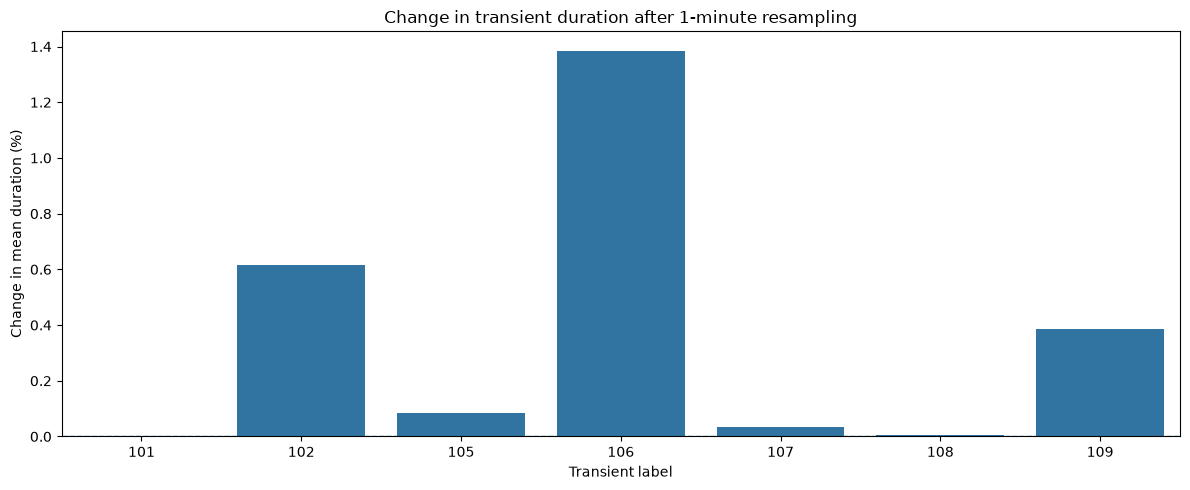

In [42]:
plot_data = final_transient_comparison.reset_index()

plot_data["mean_duration_change_pct"] = (
    100
    * (
        plot_data["mean_duration_1min"]
        - plot_data["mean_duration_raw"]
    )
    / plot_data["mean_duration_raw"]
)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=plot_data,
    x="label",
    y="mean_duration_change_pct",
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("Transient label")
plt.ylabel("Change in mean duration (%)")
plt.title("Change in transient duration after 1-minute resampling")
plt.tight_layout()
plt.show()

## Calcular a cobertura de cada período original

In [43]:
def calculate_period_coverage(
    raw_periods,
    resampled_periods,
):
    results = []

    for raw in raw_periods.to_dict("records"):
        candidates = resampled_periods[
            (resampled_periods["event_id"] == raw["event_id"])
            & (resampled_periods["label"] == raw["label"])
        ]

        overlaps = []

        for minute in candidates.to_dict("records"):
            overlap = calculate_overlap(raw, minute)

            if overlap > 0:
                overlaps.append({
                    "start": max(raw["start"], minute["start"]),
                    "end": min(
                        raw["end_exclusive"],
                        minute["end_exclusive"],
                    ),
                })

        # Unir os intervalos sobrepostos para evitar contar
        # duas vezes uma mesma região temporal.
        overlaps.sort(key=lambda x: x["start"])

        covered_seconds = 0.0
        current_start = None
        current_end = None

        for interval in overlaps:
            if current_start is None:
                current_start = interval["start"]
                current_end = interval["end"]
            elif interval["start"] <= current_end:
                current_end = max(current_end, interval["end"])
            else:
                covered_seconds += (
                    current_end - current_start
                ).total_seconds()

                current_start = interval["start"]
                current_end = interval["end"]

        if current_start is not None:
            covered_seconds += (
                current_end - current_start
            ).total_seconds()

        raw_duration = raw["duration_seconds"]

        coverage = (
            covered_seconds / raw_duration
            if raw_duration > 0
            else np.nan
        )

        results.append({
            "event_id": raw["event_id"],
            "file_name": raw["file_name"],
            "label": raw["label"],
            "raw_duration_seconds": raw_duration,
            "covered_seconds": covered_seconds,
            "coverage_percent": coverage * 100,
        })

    return pd.DataFrame(results)


period_coverage = calculate_period_coverage(
    periods_raw_reference,
    periods_1min_reference,
)

period_coverage.head()

,event_id,file_name,label,raw_duration_seconds,covered_seconds,coverage_percent
0,0,0/WELL-00001_20170201010207.parquet,0,17873.0,17821.0,99.709058
1,1,0/WELL-00001_20170201060114.parquet,0,17926.0,17881.0,99.748968
2,2,0/WELL-00001_20170201110124.parquet,0,17916.0,17881.0,99.804644
3,3,0/WELL-00001_20170201160311.parquet,0,17809.0,17761.0,99.730473
4,4,0/WELL-00001_20170201210228.parquet,0,17852.0,17821.0,99.826350


In [44]:
coverage_summary = (
    period_coverage
    .groupby("label")
    .agg(
        occurrences=("event_id", "count"),
        mean_coverage=("coverage_percent", "mean"),
        median_coverage=("coverage_percent", "median"),
        min_coverage=("coverage_percent", "min"),
        periods_below_95=(
            "coverage_percent",
            lambda x: (x < 95).sum(),
        ),
        periods_below_80=(
            "coverage_percent",
            lambda x: (x < 80).sum(),
        ),
    )
)

coverage_summary

,occurrences,mean_coverage,median_coverage,min_coverage,periods_below_95,periods_below_80
label,,,,,,
0,744,99.545518,99.687796,80.213904,6,0
1,4,100.000000,100.000000,100.000000,0,0
2,11,100.000000,100.000000,100.000000,0,0
3,32,99.817918,99.826350,99.668073,0,0
4,343,99.509041,99.480191,99.169131,0,0
5,7,100.000000,100.000000,100.000000,0,0
6,6,100.000000,100.000000,100.000000,0,0
7,5,100.000000,100.000000,100.000000,0,0
8,12,100.000000,100.000000,100.000000,0,0


## Lacunas na série de rótulos

In [45]:
def label_gap_statistics(event, resolution):
    labels = event["data"]["class"].dropna()

    if resolution == "1min":
        labels = labels.resample("1min").last().dropna()

    index = pd.DatetimeIndex(labels.index).sort_values()

    if len(index) < 2:
        return None

    delta = np.diff(index.asi8) / 1e9

    expected_interval = (
        1.0 if resolution == "1s" else 60.0
    )

    gaps = delta > expected_interval * GAP_FACTOR

    return {
        "event_id": event["event_id"],
        "file_name": event["file_name"],
        "resolution": resolution,
        "n_observations": len(index),
        "n_gaps": int(gaps.sum()),
        "total_gap_seconds": float(delta[gaps].sum()),
        "max_gap_seconds": (
            float(delta[gaps].max())
            if gaps.any() else 0.0
        ),
    }


label_gaps = []

for event in events:
    result = label_gap_statistics(event, "1s")
    if result is not None:
        label_gaps.append(result)

    result = label_gap_statistics(event, "1min")
    if result is not None:
        label_gaps.append(result)

label_gaps = pd.DataFrame(label_gaps)

label_gaps.groupby("resolution").agg(
    instances=("event_id", "nunique"),
    total_gaps=("n_gaps", "sum"),
    total_gap_seconds=("total_gap_seconds", "sum"),
    max_gap_seconds=("max_gap_seconds", "max"),
)

,instances,total_gaps,total_gap_seconds,max_gap_seconds
resolution,,,,
1min,1119,0,0.0,0.0
1s,1119,0,0.0,0.0


# Disponibilidade de janelas de 64 amostras:

In [46]:
import numpy as np
import pandas as pd

WINDOW_SIZE = 64
WINDOW_STRIDE = 1

MASK_SIZES = [8, 16, 32]

TRANSIENT_LABELS = [101, 102, 105, 106, 107, 108, 109]

EXPECTED_INTERVAL = pd.Timedelta(minutes=1)

## Separar trechos contínuos e válidos
Esta função separa cada instância em segmentos contínuos. Uma amostra com algum sinal ausente também interrompe o segmento, pois não queremos formar janelas incompletas.

In [47]:
def get_valid_segments(
    event,
    signal_columns=SIGNAL_COLUMNS,
    expected_interval=EXPECTED_INTERVAL,
):
    df = event["data"].copy()

    df.index = pd.to_datetime(df.index)
    df = df.sort_index()

    required_columns = signal_columns + ["class"]

    missing_columns = [
        col for col in required_columns
        if col not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing columns: {missing_columns}"
        )

    # Ensure that all signals are numeric.
    signals = df[signal_columns].apply(
        pd.to_numeric,
        errors="coerce",
    )

    # A row is valid only if all signals and its label are available.
    valid = (
        signals.notna().all(axis=1)
        & np.isfinite(signals).all(axis=1)
        & df["class"].notna()
    )

    df = df.loc[valid, required_columns].copy()

    if df.empty:
        return []

    # A new segment starts whenever the interval is not exactly 1 minute.
    time_diff = df.index.to_series().diff()

    segment_id = (
        time_diff.ne(expected_interval)
        .cumsum()
    )

    return [
        segment.copy()
        for _, segment in df.groupby(segment_id)
        if len(segment) >= WINDOW_SIZE
    ]

## Extrair todas as janelas
Além de contar as janelas, vamos registrar algumas características de cada uma:
- Label predominante.
- Quantidade de labels distintos.
- Quantidade de amostras transientes.
- Se a janela contém apenas um label.
- Quantos blocos de cada tamanho podem ser posicionados inteiramente dentro de um período transiente.

In [48]:
def count_transient_mask_positions(labels, mask_size):
    """
    Count possible contiguous mask positions that fall entirely
    within transient-label runs.
    """
    is_transient = np.isin(labels, TRANSIENT_LABELS)

    changes = np.diff(
        np.r_[False, is_transient, False].astype(int)
    )

    run_starts = np.where(changes == 1)[0]
    run_ends = np.where(changes == -1)[0]

    return sum(
        max(0, end - start - mask_size + 1)
        for start, end in zip(run_starts, run_ends)
    )


def extract_windows(events):
    records = []

    for event_idx, event in enumerate(events):
        segments = get_valid_segments(event)

        event_id = event.get(
            "event_id",
            event.get("file_name", event_idx),
        )

        event_class = event.get("event_class", np.nan)

        for segment_idx, segment in enumerate(segments):
            labels = segment["class"].to_numpy()

            n_windows = (
                (len(segment) - WINDOW_SIZE) // WINDOW_STRIDE
            ) + 1

            for window_idx in range(0, n_windows * WINDOW_STRIDE,
                                    WINDOW_STRIDE):

                window = segment.iloc[
                    window_idx:window_idx + WINDOW_SIZE
                ]

                window_labels = labels[
                    window_idx:window_idx + WINDOW_SIZE
                ]

                unique_labels, counts = np.unique(
                    window_labels,
                    return_counts=True,
                )

                dominant_label = unique_labels[
                    np.argmax(counts)
                ]

                record = {
                    "event_id": event_id,
                    "event_class": event_class,
                    "segment_id": segment_idx,
                    "start": window.index[0],
                    "end": window.index[-1],
                    "dominant_label": dominant_label,
                    "n_unique_labels": len(unique_labels),
                    "labels_present": tuple(unique_labels.tolist()),
                    "homogeneous": len(unique_labels) == 1,
                    "transient_samples": int(
                        np.isin(
                            window_labels,
                            TRANSIENT_LABELS,
                        ).sum()
                    ),
                    "contains_transient": bool(
                        np.isin(
                            window_labels,
                            TRANSIENT_LABELS,
                        ).any()
                    ),
                }

                for mask_size in MASK_SIZES:
                    record[f"transient_mask_{mask_size}"] = (
                        count_transient_mask_positions(
                            window_labels,
                            mask_size,
                        )
                    )

                records.append(record)

    return pd.DataFrame(records)


windows_1min = extract_windows(events_1min)

print(f"Total valid windows: {len(windows_1min):,}")

windows_1min.head()

Total valid windows: 68,780


,event_id,event_class,segment_id,start,end,dominant_label,n_unique_labels,labels_present,homogeneous,transient_samples,contains_transient,transient_mask_8,transient_mask_16,transient_mask_32
0,0,0,0,2017-02-01 02:02:00,2017-02-01 03:05:00,0,1,"(0,)",True,0,False,0,0,0
1,0,0,0,2017-02-01 02:03:00,2017-02-01 03:06:00,0,1,"(0,)",True,0,False,0,0,0
2,0,0,0,2017-02-01 02:04:00,2017-02-01 03:07:00,0,1,"(0,)",True,0,False,0,0,0
3,0,0,0,2017-02-01 02:05:00,2017-02-01 03:08:00,0,1,"(0,)",True,0,False,0,0,0
4,0,0,0,2017-02-01 02:06:00,2017-02-01 03:09:00,0,1,"(0,)",True,0,False,0,0,0


In [49]:
availability_summary = pd.DataFrame([{
    "total_windows": len(windows_1min),
    "homogeneous_windows": windows_1min["homogeneous"].sum(),
    "mixed_label_windows": (~windows_1min["homogeneous"]).sum(),
    "windows_with_transient": windows_1min["contains_transient"].sum(),
    "windows_without_transient": (~windows_1min["contains_transient"]).sum(),
}])

availability_summary

,total_windows,homogeneous_windows,mixed_label_windows,windows_with_transient,windows_without_transient
0,68780,67540,1240,10483,58297


## Disponibilidade por label
Para não considerar somente o label predominante, vamos registrar todos os labels presentes em cada janela.

In [50]:
windows_by_label = (
    windows_1min
    .explode("labels_present")
    .groupby("labels_present")
    .agg(
        windows=("event_id", "size"),
        homogeneous_windows=("homogeneous", "sum"),
        windows_with_transient=("contains_transient", "sum"),
    )
    .rename_axis("label")
    .sort_index()
)

windows_by_label

,windows,homogeneous_windows,windows_with_transient
label,,,
0,55893,55004,889
1,117,15,102
2,20,0,20
3,238,238,0
4,2686,2686,0
5,188,63,125
7,426,291,135
101,1081,790,1081
102,50,0,50


## Adequação aos blocos de mascaramento
Agora vamos verificar quantas janelas possuem trechos transientes suficientemente longos para receber cada bloco de mascaramento.

In [51]:
mask_summary = []

for mask_size in MASK_SIZES:
    placements_col = f"transient_mask_{mask_size}"

    eligible = windows_1min[placements_col] > 0

    mask_summary.append({
        "mask_size": mask_size,
        "total_windows": len(windows_1min),
        "windows_with_transient_mask": eligible.sum(),
        "windows_without_transient_mask": (~eligible).sum(),
        "total_possible_transient_masks": (
            windows_1min[placements_col].sum()
        ),
        "percentage_eligible": (
            100 * eligible.mean()
            if len(windows_1min) else np.nan
        ),
    })

mask_summary = pd.DataFrame(mask_summary)

mask_summary

,mask_size,total_windows,windows_with_transient_mask,windows_without_transient_mask,total_possible_transient_masks,percentage_eligible
0,8,68780,10371,58409,560667,15.078511
1,16,68780,10227,58553,478203,14.869148
2,32,68780,9939,58841,316731,14.450422


## Adequação por label transiente
Esta análise é especialmente importante para verificar se temos dados suficientes para estudar a reconstrução dos períodos transientes individualmente.

In [52]:
transient_windows = (
    windows_1min[
        windows_1min["contains_transient"]
    ]
    .explode("labels_present")
)

transient_windows = transient_windows[
    transient_windows["labels_present"].isin(
        TRANSIENT_LABELS
    )
]

transient_mask_summary = []

for label, group in transient_windows.groupby("labels_present"):
    row = {
        "label": label,
        "windows": len(group),
    }

    for mask_size in MASK_SIZES:
        col = f"transient_mask_{mask_size}"

        row[f"eligible_{mask_size}"] = (
            group[col].gt(0).sum()
        )

        row[f"possible_masks_{mask_size}"] = (
            group[col].sum()
        )

    transient_mask_summary.append(row)

transient_mask_summary = pd.DataFrame(
    transient_mask_summary
).set_index("label").sort_index()

transient_mask_summary

,windows,eligible_8,possible_masks_8,eligible_16,possible_masks_16,eligible_32,possible_masks_32
label,,,,,,,
101,1081,1053,53225,1021,44913,957,29057
102,50,48,966,40,610,24,90
105,5330,5277,286991,5213,244999,5085,162551
107,4021,3993,219485,3953,187681,3873,125033
109,1,0,0,0,0,0,0


## Distribuição de janelas homogêneas e heterogêneas
Por fim, vamos verificar quantas janelas contêm apenas um label e quantas incluem transições.

In [53]:
label_composition = (
    windows_1min
    .groupby("n_unique_labels")
    .size()
    .rename("windows")
    .to_frame()
)

label_composition["percentage"] = (
    100 * label_composition["windows"]
    / len(windows_1min)
)

label_composition

,windows,percentage
n_unique_labels,,
1,67540,98.197150
2,1209,1.757778
3,31,0.045071
